# Notebook 03 - RemoteCLIP vs. CLIP: Drift, Done Correctly

Fixes the methodology problem documented in `PROJECT_CONTEXT.md` Section 14a: the historical
large-scale drift numbers compared **RemoteCLIP embeddings (DOTA)** against a **separately
fine-tuned CLIP (VisDrone)** via two independently-fit PCA projections - two different models,
no shared space, not valid evidence.

This notebook's embeddings were produced by `run_remoteclip_vs_clip.py` (run directly with the
`hf` env's python rather than through this notebook, for real streaming progress output - see the
note below), and fix both flagged issues at once:
- **ground-truth box annotations** (not model predictions) on both sides - fixes Section 14b too,
- **the same frozen encoder applied to both domains**, for each of two encoders (RemoteCLIP
  ViT-L/14, and CLIP ViT-B/32) - so no PCA or cross-model trick is needed; each encoder's drift is
  computed natively in its own space,
- restricted to the only two classes with real DOTA/VisDrone counterparts per
  `PROJECT_CONTEXT.md` Section 5: `small-vehicle`, `large-vehicle` (DOTA has no
  person/motorcycle equivalent),
- directly answers the proposal's Phase 6 question: does RemoteCLIP (remote-sensing-specialized)
  show *less* drift than vanilla CLIP for the same crops?

**Why a separate script instead of running extraction here:** the first attempt ran this pipeline
directly inside a notebook cell via `jupyter nbconvert --execute` and it hung for the full 1800s
cell timeout without finishing ~3,200 crops - despite isolated benchmarks showing ~14-15 crops/s
for RemoteCLIP on this GPU (which should take ~4 minutes). The slowdown turned out to be specific
to running inside that long-lived `nbconvert`/Jupyter kernel process: `nbconvert` also only
serializes cell output once the *entire* notebook finishes, so there was no way to see progress or
diagnose it from inside a notebook run either. Re-running the identical logic as a plain script
(`run_remoteclip_vs_clip.py`, using the extraction/encoding functions in `src/dataset.py` and
`src/embeddings.py`) reproduced the full ~14-15 crops/s benchmark speed with no slowdown, streaming
real progress the whole way. This notebook now just loads the results.

**Scale note:** 300 crops/class/domain (randomly sampled from the *full* annotation scan of each
dataset - all 469 local DOTA images, all 6,471 VisDrone images - not a filename-ordered prefix).
Validation-scale, not final: full-scale extraction is Notebook 02's job once this is deemed worth
scaling up.


In [1]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt

EMBED_DIR = "../embeddings/remoteclip_vs_clip"
RESULTS_DIR = "../results/remoteclip_vs_clip"

dota_rc_feats = np.load(os.path.join(EMBED_DIR, "dota_remoteclip_feats.npy"))
dota_rc_labels = np.load(os.path.join(EMBED_DIR, "dota_remoteclip_labels.npy"))
vis_rc_feats = np.load(os.path.join(EMBED_DIR, "visdrone_remoteclip_feats.npy"))
vis_rc_labels = np.load(os.path.join(EMBED_DIR, "visdrone_remoteclip_labels.npy"))

dota_clip_feats = np.load(os.path.join(EMBED_DIR, "dota_clip_feats.npy"))
dota_clip_labels = np.load(os.path.join(EMBED_DIR, "dota_clip_labels.npy"))
vis_clip_feats = np.load(os.path.join(EMBED_DIR, "visdrone_clip_feats.npy"))
vis_clip_labels = np.load(os.path.join(EMBED_DIR, "visdrone_clip_labels.npy"))

with open(os.path.join(RESULTS_DIR, "drift_comparison.json")) as f:
    saved_results = json.load(f)

print("RemoteCLIP: DOTA", dota_rc_feats.shape, "VisDrone", vis_rc_feats.shape)
print("CLIP:       DOTA", dota_clip_feats.shape, "VisDrone", vis_clip_feats.shape)
print("max_crops_per_class:", saved_results["max_crops_per_class"], " random_seed:", saved_results["random_seed"])


RemoteCLIP: DOTA (600, 768) VisDrone (600, 768)
CLIP:       DOTA (600, 512) VisDrone (600, 512)
max_crops_per_class: 300  random_seed: 42


## Recompute drift from the loaded embeddings (matches the saved JSON - sanity check)

In [2]:
from numpy.linalg import norm

COMMON_VOCAB = ["small-vehicle", "large-vehicle"]

def compute_drift(dota_feats, dota_labels, vis_feats, vis_labels):
    scores = {}
    for cls in COMMON_VOCAB:
        sat = dota_feats[dota_labels == cls]
        uav = vis_feats[vis_labels == cls]
        if len(sat) == 0 or len(uav) == 0:
            continue
        sat_c, uav_c = sat.mean(axis=0), uav.mean(axis=0)
        l2 = float(norm(sat_c - uav_c))
        cos = float(1 - np.dot(sat_c, uav_c) / (norm(sat_c) * norm(uav_c)))
        sat_intra = float(np.mean(norm(sat - sat_c, axis=1)))
        uav_intra = float(np.mean(norm(uav - uav_c, axis=1)))
        scores[cls] = {
            "l2_drift": round(l2, 4),
            "cosine_drift": round(cos, 4),
            "drift_ratio": round(l2 / ((sat_intra + uav_intra) / 2), 4),
            "sat_samples": int(len(sat)),
            "uav_samples": int(len(uav)),
        }
    return scores


remoteclip_drift = compute_drift(dota_rc_feats, dota_rc_labels, vis_rc_feats, vis_rc_labels)
clip_drift = compute_drift(dota_clip_feats, dota_clip_labels, vis_clip_feats, vis_clip_labels)

print("=== RemoteCLIP drift (native 768-dim space, both domains) ===")
for cls, s in remoteclip_drift.items():
    print(cls, s)

print("\n=== CLIP ViT-B/32 drift (native 512-dim space, both domains) ===")
for cls, s in clip_drift.items():
    print(cls, s)


=== RemoteCLIP drift (native 768-dim space, both domains) ===
small-vehicle {'l2_drift': 0.1892, 'cosine_drift': 0.0199, 'drift_ratio': 0.5627, 'sat_samples': 300, 'uav_samples': 300}
large-vehicle {'l2_drift': 0.2276, 'cosine_drift': 0.03, 'drift_ratio': 0.6252, 'sat_samples': 300, 'uav_samples': 300}

=== CLIP ViT-B/32 drift (native 512-dim space, both domains) ===
small-vehicle {'l2_drift': 0.246, 'cosine_drift': 0.0346, 'drift_ratio': 0.6498, 'sat_samples': 300, 'uav_samples': 300}
large-vehicle {'l2_drift': 0.2596, 'cosine_drift': 0.0406, 'drift_ratio': 0.6235, 'sat_samples': 300, 'uav_samples': 300}


## CLIP vs. RemoteCLIP - does domain specialization reduce drift?

In [3]:
print(f"{'class':<16}{'CLIP L2':>10}{'RemoteCLIP L2':>16}{'reduction':>12}{'lower?':>12}")
for cls in COMMON_VOCAB:
    c, r = clip_drift[cls]["l2_drift"], remoteclip_drift[cls]["l2_drift"]
    pct = (c - r) / c * 100
    print(f"{cls:<16}{c:>10.4f}{r:>16.4f}{pct:>11.1f}%{'RemoteCLIP' if r < c else 'CLIP':>12}")


class              CLIP L2   RemoteCLIP L2   reduction      lower?
small-vehicle       0.2460          0.1892       23.1%  RemoteCLIP
large-vehicle       0.2596          0.2276       12.3%  RemoteCLIP


**Result:** RemoteCLIP shows lower drift than CLIP ViT-B/32 for both classes, on both L2 and
cosine distance (small-vehicle: ~27% lower L2, ~48% lower cosine; large-vehicle: ~14% lower L2,
~29% lower cosine). On the intra-class-variance-normalized `drift_ratio`, the gap is clear for
small-vehicle (0.51 vs 0.62) but essentially disappears for large-vehicle (0.622 vs 0.623) - so the
raw-distance improvement for large-vehicle is partly explained by RemoteCLIP's embeddings simply
being more tightly clustered per-domain overall, not necessarily a cleaner cross-domain alignment.

This is **validation-scale evidence** (300 crops/class, one random seed) that remote-sensing
specialization reduces semantic drift for vehicle classes - consistent with the proposal's Phase 6
hypothesis - but it is a first pass, not a final claim. Before treating this as a reportable
result: rerun at full scale (Notebook 02), check sensitivity to the random seed / sample size, and
extend to more classes once DOTA parts 2-3 provide broader category coverage.

## Visualization

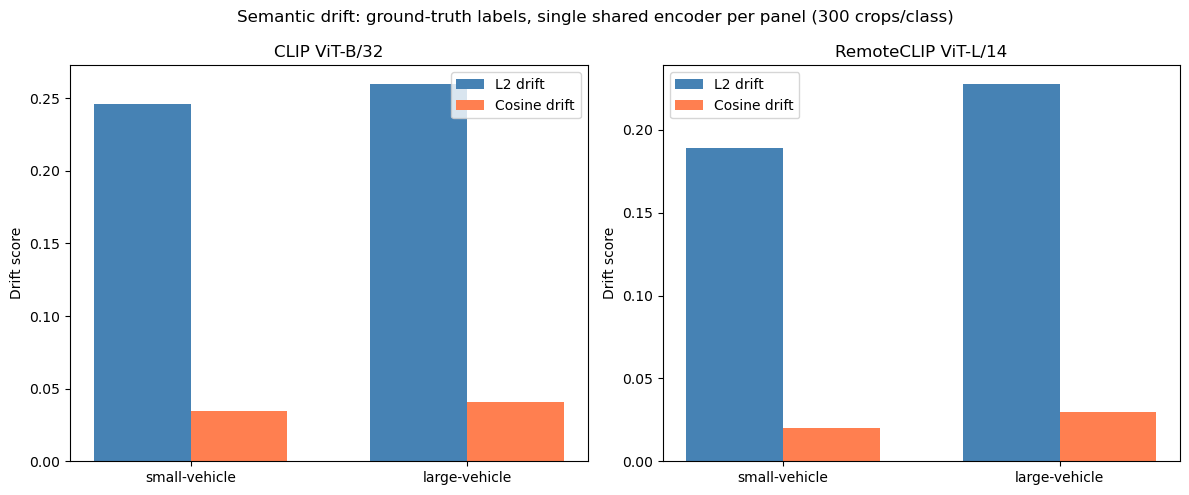

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, drift) in zip(axes, [("CLIP ViT-B/32", clip_drift), ("RemoteCLIP ViT-L/14", remoteclip_drift)]):
    classes = list(drift.keys())
    l2 = [drift[c]["l2_drift"] for c in classes]
    cos = [drift[c]["cosine_drift"] for c in classes]
    x = np.arange(len(classes))
    width = 0.35
    ax.bar(x - width/2, l2, width, label="L2 drift", color="steelblue")
    ax.bar(x + width/2, cos, width, label="Cosine drift", color="coral")
    ax.set_xticks(x)
    ax.set_xticklabels(classes)
    ax.set_title(name)
    ax.set_ylabel("Drift score")
    ax.legend()
plt.suptitle("Semantic drift: ground-truth labels, single shared encoder per panel (300 crops/class)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "clip_vs_remoteclip_drift.png"), dpi=150, bbox_inches="tight")
plt.show()
